In [1]:
import jpype
import os
from jpype import JClass

jar_path = os.path.abspath("infodynamics.jar")
jpype.startJVM(classpath=[jar_path])

TECalcClass = jpype.JPackage("infodynamics.measures.continuous.kraskov").TransferEntropyCalculatorKraskov
teCalc = TECalcClass()

from jpype import JPackage
CTEClass = JPackage("infodynamics.measures.continuous.kraskov").ConditionalTransferEntropyCalculatorKraskov
cteCalc = CTEClass()

MIClass = jpype.JPackage("infodynamics.measures.continuous.kraskov").MutualInfoCalculatorMultiVariateKraskov1
miCalc = MIClass()

In [2]:
import sys
sys.path.insert(0,r"C:\Users\alons\Master Ciencia de Datos/TFM/Git Hub/notebooks/IDTxl-master/IDTxl-master")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from typing import Tuple
from tqdm import tqdm
import pandas as pd

import math
np.math = math
from idtxl.multivariate_te import MultivariateTE
from idtxl.data import Data
from idtxl.visualise_graph import plot_network
from sklearn.feature_selection import mutual_info_regression

from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression

from scipy.stats import gaussian_kde, ks_2samp
from scipy.signal import welch

%load_ext autoreload
%autoreload 2
from pathlib import Path

ruta_scripts = Path.cwd().parent / "scripts"
sys.path.append(str(ruta_scripts))

import Modelos_neuronales as mn

In [84]:
def find_optimal_tau_TE_JIDT(V1, V2, n_vecinos, max_steps=600, contexto_k=5, contexto_l=5, contexto_c=1, factor_bool=True, plot=False, inverse=False, conditional=False, padres_source=None):
    """
    Calcula la Transfer Entropy (TE) para distintos valores de tau_source con el código de JIDT.
    Si inverse=True:
        calcula también V2 -> V1.
    Si conditional=True:
        calcula también la CTE V1 -> V2 | V2
    Retorna:
        tau_values, te_direct, optimal_tau

    """
    tau_values = np.arange(1, max_steps + 1)
    te_results = []

    if inverse:
        te_inverse_results = []
        
    if conditional:
        cte_results = []
    
    factor = 5   

    if factor_bool:
        V1 = V1[::factor]
        V2 = V2[::factor]

    hist = max(contexto_k, contexto_l, contexto_c)
    V1 = V1[hist:]
    V2 = V2[hist:]
        
        # --- TE Directa (V1 -> V2) ---
    teCalc = TECalcClass()
    teCalc.setProperty("k", str(n_vecinos))
    teCalc.setProperty("k_HISTORY", str(contexto_k))
    teCalc.setProperty("l_HISTORY", str(contexto_l))
    

    for tau in tqdm(tau_values, desc="Análisis de Tau", unit="tau"):
        
        teCalc.setProperty("DELAY", str(tau))
        teCalc.initialise()
        teCalc.setObservations(V1.astype(np.float64), V2.astype(np.float64))
        te = teCalc.computeAverageLocalOfObservations()
        te_results.append(te)

         # --- TE Inversa (V2 -> V1) ---
    if inverse:
    
            teCalc_inv = TECalcClass()
            teCalc_inv.setProperty("k", str(n_vecinos))
            teCalc_inv.setProperty("k_HISTORY", str(contexto_k))
            teCalc_inv.setProperty("l_HISTORY", str(contexto_l))
    
            for tau in tqdm(tau_values, desc="TE V2 → V1", unit="tau"):
                teCalc_inv.setProperty("DELAY", str(tau))
                teCalc_inv.initialise()
                teCalc_inv.setObservations(V2.astype(np.float64),V1.astype(np.float64))
                te_inv = teCalc_inv.computeAverageLocalOfObservations()
                te_inverse_results.append(te_inv)
                

        # --- CTE (V1 -> V2 | V2) ---
    if conditional:
        cteCalc = CTEClass() 
        cteCalc.setProperty("k", str(n_vecinos))
        cteCalc.setProperty("k_HISTORY", str(contexto_k))
        cteCalc.setProperty("l_HISTORY", str(contexto_l))
        cteCalc.setProperty("c_HISTORY", str(contexto_c))
    
        for tau in tqdm(tau_values, desc="CTE V1 → V2 | V2", unit="tau"):
            cteCalc.setProperty("DELAY", str(tau))
            cteCalc.initialise()
            cteCalc.setObservations(V1.astype(np.float64), V2.astype(np.float64), V2.astype(np.float64))
            cte_val = cteCalc.computeAverageLocalOfObservations()
            cte_results.append(cte_val)


    te_results = np.array(te_results)
    if inverse:
        te_inverse_results = np.array(te_inverse_results)
    if conditional:
        cte_results = np.array(cte_results)

    optimal_idx = np.argmax(te_results)
    optimal_tau = tau_values[optimal_idx]
    
    if factor_bool:
        optimal_tau = optimal_tau * factor
        tau_values = tau_values * factor

    # Gráfica
    if plot:

        plt.figure(figsize=(10, 6))
        plt.plot(tau_values, te_results, lw=2, label="Transfer Entropy (Direct)")
        if padres_source is not None:
            if np.isscalar(padres_source):
                padres_source = [padres_source]
            for i, delay in enumerate(padres_source):
                if delay in tau_values:
                    idx = np.where(tau_values == delay)[0][0]
                    plt.scatter(tau_values[idx], te_results[idx], marker="*", s=250, zorder=5, label="Padre seleccionado" if i == 0 else None)
        if inverse:
            plt.plot(tau_values, te_inverse_results, color="gray", alpha=0.45, lw=1.8, linestyle="--", label="TE V2 → V1")
        if conditional:
            plt.plot(tau_values, cte_results, color="red", alpha=0.35, lw=1.8, linestyle="--", label="CTE V1 → V2 | V2")
        plt.axvline(tau_values[optimal_idx], linestyle="--", alpha=0.7)
        plt.xlabel("Delay")
        plt.ylabel("Transfer Entropy")
        plt.title(f"TE (JIDT-Kraskov) vs Delay "f"(k={n_vecinos})")
        plt.grid(True)
        plt.legend()
        plt.show()


    return tau_values, te_results, optimal_tau

In [11]:
def find_optimal_tau_MI(V1, V2, n_vecinos, dt=0.01, max_lags=600, milisegundos = True, plot=False):
    """
    Calcula la Información Mutua para diferentes retardos (tau). El retardo consiste en desplazar V2 respecto a V1.
    """
    
    lags = np.arange(0, max_lags)
    mi_results = []
    factor=5 

    v1_fixed = V1[:-(max_lags)]
    
    for lag in tqdm(lags, desc="Análisis de Tau", unit="lag"):
        v2_shifted = V2[lag : lag + len(v1_fixed)]
        
        mi = mutual_info_regression(v1_fixed[::factor].reshape(-1, 1), v2_shifted[::factor], n_neighbors= n_vecinos, discrete_features=False)
        mi_results.append(mi[0])
        
    mi_results = np.array(mi_results)
    
    # Encontrar el óptimo
    optimal_idx = np.argmax(mi_results)
    optimal_tau = lags[optimal_idx]

    if milisegundos:
        x_values = lags * dt
        optimal_tau = optimal_tau *dt
        xlabel = r"$\tau$ (ms)"
    else:
        x_values = lags
        xlabel = r"$\tau$ (pasos)"

    # Gráfica
    if plot:

        plt.figure(figsize=(10, 6))
        plt.plot(x_values, mi_results, lw=2, label="Información mutua")
        plt.scatter(x_values[optimal_idx], mi_results[optimal_idx], marker="*", s=250, zorder=5, label=f"Óptimo: τ={optimal_tau:.3f}")
        plt.axvline( x_values[optimal_idx], linestyle="--", alpha=0.7)
        plt.xlabel(xlabel)
        plt.ylabel("Mutual Information")
        plt.title(
            f"MI vs τ (k={n_vecinos})"
        )
        plt.grid(True)
        plt.legend()
        plt.show()
        
    return mi_results, optimal_tau

In [12]:
def distribucion_testKS(
    serie_original,
    surrogates,
    n_points=300,
    alpha=0.05,
    bandas="std",          # "std" o "percentil"
    plot=True
):
    """
    Compara la distribución de una serie original con un conjunto de surrogates.

    Parámetros
    ----------
    serie_original : array_like
        Serie temporal original.

    surrogates : ndarray (n_surrogates, N)
        Cada fila corresponde a un surrogate.

    n_points : int
        Número de puntos para estimar la KDE.

    alpha : float
        Nivel de significación para el test KS (se hace uno para cada surrogate).

    bandas : str
        "std"       -> media ± desviación típica.
        "percentil" -> intervalo 2.5%-97.5%.

    plot : bool
        Si True dibuja las densidades.

    Devuelve
    --------
    resultados : dict
        Diccionario con estadísticas y resultados del test KS.
    """

    serie_original = np.asarray(serie_original)
    surrogates = np.asarray(surrogates)
    if surrogates.ndim != 2:
        raise ValueError("surrogates debe ser una matriz (n_surrogates, N).")
    n_surrogates = surrogates.shape[0]

    # ==========================================================
    # Estadísticos básicos

    media_original = np.mean(serie_original)
    var_original = np.var(serie_original)
    medias_surrogates = np.mean(surrogates, axis=1)
    vars_surrogates = np.var(surrogates, axis=1)
    print("\n========== Estadísticos ==========")
    print(f"Media original              : {media_original:.6f}")
    print(f"Media de las medias surrogate: {np.mean(medias_surrogates):.6f}")
    print()
    print(f"Varianza original              : {var_original:.6f}")
    print(f"Media de las varianzas surrogate: {np.mean(vars_surrogates):.6f}")

    # ==========================================================
    # Estimación de densidades

    xmin = min(np.min(serie_original), np.min(surrogates))
    xmax = max(np.max(serie_original), np.max(surrogates))
    margen = 0.05 * (xmax - xmin)
    x = np.linspace(xmin - margen, xmax + margen, n_points)
    kde_original = gaussian_kde(serie_original)
    dens_original = kde_original(x)
    dens_surrogates = np.zeros((n_surrogates, n_points))

    for i in range(n_surrogates):
        kde = gaussian_kde(surrogates[i])
        dens_surrogates[i] = kde(x)
    media_dens = np.mean(dens_surrogates, axis=0)

    if bandas == "std":
        banda_inf = media_dens - np.std(dens_surrogates, axis=0)
        banda_sup = media_dens + np.std(dens_surrogates, axis=0)
    elif bandas == "percentil":
        banda_inf = np.percentile(dens_surrogates, 2.5, axis=0)
        banda_sup = np.percentile(dens_surrogates, 97.5, axis=0)

    # ==========================================================
    # Test KS

    estadisticos = []
    pvalues = []

    for s in surrogates:
        D, p = ks_2samp(serie_original, s)
        estadisticos.append(D)
        pvalues.append(p)

    estadisticos = np.array(estadisticos)
    pvalues = np.array(pvalues)
    rechazados = pvalues < alpha

    print("\n========== Test Kolmogorov-Smirnov ==========")
    print(f"Número de surrogates          : {n_surrogates}")
    print(f"Nivel de significación        : {alpha}")
    print(f"Rechazos de H0               : {np.sum(rechazados)}/{n_surrogates}")
    print(f"Porcentaje de rechazos       : {100*np.mean(rechazados):.2f}%")
    print(f"Estadístico D medio          : {np.mean(estadisticos):.5f}")
    print(f"p-valor medio                : {np.mean(pvalues):.5f}")

    # ==========================================================
    # Gráfica

    if plot:
        plt.figure(figsize=(8,5))
        plt.plot(x, dens_original, lw=2.5, label="Serie original")
        plt.plot(x, media_dens, lw=2, label="Media surrogates")
        plt.fill_between(x, banda_inf, banda_sup, alpha=0.3, label="Banda")
        plt.xlabel("Valor")
        plt.ylabel("Densidad")
        plt.title("Comparación de funciones de densidad")
        plt.legend()
        plt.tight_layout()
        plt.show()

    resultados = {
        "media_original": media_original,
        "var_original": var_original,
        "media_surrogates": np.mean(medias_surrogates),
        "var_surrogates": np.mean(vars_surrogates),
        "ks_D": estadisticos,
        "ks_pvalue": pvalues,
        "rechazados": rechazados,
        "porcentaje_rechazo": 100*np.mean(rechazados)
    }

    return resultados

In [13]:
def PSD_autocorrelacion(
    serie_original,
    surrogates,
    fs=1.0,
    max_lag=100,
    nperseg=None,
    bandas="std",
    plot=True,
):
    """
    Compara la PSD y la autocorrelación lineal entre una serie original y un conjunto de surrogates.

    Parámetros
    ----------
    serie_original : array_like

    surrogates : ndarray (n_surrogates, N)

    fs : float
        Frecuencia de muestreo para Welch.

    max_lag : int
        Máximo retardo para la autocorrelación.

    nperseg : int o None
        Parámetro de scipy.signal.welch.

    bandas : {"std","percentil"}

    plot : bool
    """

    serie_original = np.asarray(serie_original)
    surrogates = np.asarray(surrogates)
    if surrogates.ndim != 2:
        raise ValueError("surrogates debe ser una matriz.")
    n_surrogates = surrogates.shape[0]

    # ==========================================================
    # PSD

    f, psd_original = welch(serie_original, fs=fs, nperseg=nperseg)
    psd_surrogates = []

    for s in surrogates:
        _, psd = welch(s, fs=fs, nperseg=nperseg)
        psd_surrogates.append(psd)
    psd_surrogates = np.asarray(psd_surrogates)
    media_psd = np.mean(psd_surrogates, axis=0)

    if bandas == "std":
        inf_psd = media_psd - np.std(psd_surrogates, axis=0)
        sup_psd = media_psd + np.std(psd_surrogates, axis=0)
    else:
        inf_psd = np.percentile(psd_surrogates, 2.5, axis=0)
        sup_psd = np.percentile(psd_surrogates, 97.5, axis=0)

    # ==========================================================
    # AUTOCORRELACIÓN

    def autocorr(x, max_lag):     #autocorrelación normalizada
        x = x - np.mean(x)
        ac = np.correlate(x, x, mode="full")
        ac = ac[ac.size // 2:]
        ac = ac / ac[0]
        return ac[: max_lag + 1]

    ac_original = autocorr(serie_original, max_lag)
    ac_surrogates = np.array([autocorr(s, max_lag)for s in surrogates])
    media_ac = np.mean(ac_surrogates, axis=0)
    if bandas == "std":
        inf_ac = media_ac - np.std(ac_surrogates, axis=0)
        sup_ac = media_ac + np.std(ac_surrogates, axis=0)
    else:
        inf_ac = np.percentile(ac_surrogates, 2.5, axis=0)
        sup_ac = np.percentile(ac_surrogates, 97.5, axis=0)

    # ==========================================================
    # MÉTRICAS

    error_psd = np.mean(np.abs(psd_original - media_psd) / np.maximum(psd_original, 1e-12))
    error_ac = np.mean(np.abs(ac_original - media_ac))

    print("\n========== PSD ==========")
    print(f"Error relativo medio PSD: {100*error_psd:.3f} %")
    print("\n========== Autocorrelación ==========")
    print(f"Error absoluto medio: {error_ac:.6f}")

    # ==========================================================
    # FIGURAS

    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(13,5))
        ax[0].plot(f, psd_original, lw=2.5, label="Original")
        ax[0].plot(f, media_psd, lw=2, label="Media surrogates")
        ax[0].fill_between(f, inf_psd, sup_psd, alpha=0.3, label="Banda")
        ax[0].set_xlabel("Frecuencia")
        ax[0].set_ylabel("PSD")
        ax[0].set_title("Densidad espectral de potencia")
        ax[0].legend()
        lags = np.arange(max_lag + 1)
        ax[1].plot(lags, ac_original, lw=2.5, label="Original")
        ax[1].plot(lags, media_ac, lw=2, label="Media surrogates")
        ax[1].fill_between(lags, inf_ac, sup_ac, alpha=0.3, label="Banda")
        ax[1].set_xlabel("Retardo")
        ax[1].set_ylabel("Autocorrelación")
        ax[1].set_title("Autocorrelación lineal")
        ax[1].legend()
        plt.tight_layout()
        plt.show()

    return {
        "frecuencias": f,
        "psd_original": psd_original,
        "psd_media": media_psd,
        "psd_surrogates": psd_surrogates,
        "autocorrelacion_original": ac_original,
        "autocorrelacion_media": media_ac,
        "autocorrelacion_surrogates": ac_surrogates,
        "error_psd": error_psd,
        "error_autocorrelacion": error_ac,
    }

In [14]:
def dMI(
    serie_original,
    surrogates,
    max_lag=100,
    n_neighbors=5,
    random_state=0,
    bandas="std",
    plot=True,
):
    """
    Compara la Información Mutua de Retardo (TDMI) entre una serie original y un conjunto de surrogates.

    Parámetros
    ----------
    serie_original : array_like

    surrogates : ndarray (n_surrogates, N)

    max_lag : int

    n_neighbors : int
        Número de vecinos para el estimador kNN.

    random_state : int

    bandas : {"std", "percentil"}

    plot : bool
    """

    serie_original = np.asarray(serie_original)
    surrogates = np.asarray(surrogates)
    if surrogates.ndim != 2:
        raise ValueError("surrogates debe ser una matriz.")

    def tdmi(x):
        mi = np.zeros(max_lag)
        miCalc = MIClass()
        miCalc.setProperty("k", str(n_neighbors))
        for tau in range(1, max_lag + 1):
            X = x[:-tau]
            Y = x[tau:]
            miCalc.initialise()
            miCalc.setObservations(X.astype(np.float64), Y.astype(np.float64))
            mi[tau - 1] = miCalc.computeAverageLocalOfObservations()
        return mi

    # Serie original
    mi_original = tdmi(serie_original)

    # Surrogates
    mi_surrogates = np.array([tdmi(s) for s in surrogates])
    media_mi = np.mean(mi_surrogates, axis=0)
    if bandas == "std":
        inf = media_mi - np.std(mi_surrogates, axis=0)
        sup = media_mi + np.std(mi_surrogates, axis=0)
    elif bandas == "percentil":
        inf = np.percentile(mi_surrogates, 2.5, axis=0)
        sup = np.percentile(mi_surrogates, 97.5, axis=0)

    # ==========================================================
    # Error medio

    error = np.mean(np.abs(mi_original - media_mi))
    print("\n========== Información Mutua de Retardo ==========")
    print(f"Error absoluto medio : {error:.6f}")
    dentro = np.logical_and(mi_original >= inf, mi_original <= sup)
    porcentaje = 100 * np.mean(dentro)
    print(f"Retardos dentro de la banda : {porcentaje:.2f}%")

    # ==========================================================
    # Figura

    if plot:
        lags = np.arange(1, max_lag + 1)
        plt.figure(figsize=(8,5))
        plt.plot(lags, mi_original, lw=2.5, label="Serie original")
        plt.plot(lags, media_mi, lw=2, label="Media surrogates")
        plt.fill_between(lags, inf, sup, alpha=0.3, label="Banda")
        plt.xlabel("Retardo")
        plt.ylabel("Información Mutua")
        plt.title("Información Mutua de Retardo")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return {
        "mi_original": mi_original,
        "mi_media": media_mi,
        "mi_surrogates": mi_surrogates,
        "error": error,
        "porcentaje_dentro": porcentaje,
        "banda_inferior": inf,
        "banda_superior": sup,
    }

In [15]:
def validacion_surrogado(
    surrogate_function,
    serie_original,
    n_surrogates=100,
    **kwargs
):
    """
    Genera un conjunto de surrogates a partir de una serie original y ejecuta las tres pruebas de validación.

    Parámetros
    ----------
    surrogate_function : callable
        Función que genera un surrogate a partir de una serie.

    serie_original : ndarray

    n_surrogates : int
        Número de surrogates a generar.

    **kwargs
        Parámetros adicionales que necesite surrogate_function
        (por ejemplo block_size, min, max...).

    Devuelve
    --------
    resultados : dict
        Diccionario con los resultados de las tres validaciones.
    """

    serie_original = np.asarray(serie_original)

    surrogates_matrix = np.array([surrogate_function(serie_original, **kwargs) for _ in range(n_surrogates)])


    # Validación de la distribución
    resultados_distribucion = distribucion_testKS(serie_original=serie_original, surrogates=surrogates_matrix, n_points=300, alpha=0.05, bandas="std", plot=True)

    # Validación de la PSD y autocorrelación
    resultados_psd = PSD_autocorrelacion(serie_original=serie_original, surrogates=surrogates_matrix, fs=1.0, max_lag=100, nperseg=None, bandas="std", plot=True)

    # Validación mediante información mutua de retardo
    resultados_dmi = dMI(serie_original=serie_original, surrogates=surrogates_matrix, max_lag=100, n_neighbors=5, random_state=0, bandas="std", plot=True)

    return {
        "surrogates": surrogates_matrix,
        "distribucion": resultados_distribucion,
        "PSD_autocorrelacion": resultados_psd,
        "dMI": resultados_dmi,
    }

In [16]:
def fft_surrogate(x):
    Xf = np.fft.fft(x)
    amplitude = np.abs(Xf)
    random_phase = np.random.uniform(0,2*np.pi,len(x))
    X_surr = amplitude * np.exp(1j * random_phase)
    return np.real(np.fft.ifft(X_surr))


def circular_surrogate(x, min = 1, max = 1):
    """
    Desplaza la serie temporal circularmente en bloque un número aleatorio de pasos.
    """
    n = len(x)
    shift = np.random.randint(min, n - max) 
    return np.roll(x, shift)


def block_surrogate(x, block_size):
    """
    Selecciona bloques de tamaño fijo con inicios aleatorios para reconstruir la serie
    y añade micro-jitter para evitar empates en estimadores KSG.
    """
    n = len(x)
    x_surr = np.empty(n)
    
    # Rellenamos la nueva serie bloque a bloque
    for i in range(0, n, block_size):
        max_start_idx = n - block_size    # Asegurar que el bloque no se salga del final de la serie original
        if max_start_idx <= 0:
            raise ValueError("El 'block_size' no puede ser mayor que la longitud de la serie.")
            
        start_idx = np.random.randint(0, max_start_idx + 1)
        end_idx = start_idx + block_size
        
        if i + block_size > n:         # Si es el último bloque y sobrepasa n, se recorta lo que falte
            remaining = n - i
            x_surr[i:] = x[start_idx : start_idx + remaining]
        else:
            x_surr[i : i + block_size] = x[start_idx : end_idx]
            
    jitter = np.random.normal(0, 1e-10, size=n)      # en IDTxl se añade ruido infinitesimal (jitter) para romper empates analíticos
    return x_surr + jitter

def local_surrogate(x, perm_range):
    """
    Estrecha los intercambios estrictamente dentro de una ventana acotada por 'perm_range' y añade micro-jitter final.
    """
    n = len(x)
    indices = np.arange(n)
    
    step = max(1, perm_range // 2)      # recorrer la serie en pasos y barajar localmente
    for i in range(0, n, step):
        # Definimos los límites de la ventana local actual
        low = max(0, i - perm_range)
        high = min(n, i + perm_range + 1)
        
        np.random.shuffle(indices[low:high])     # Barajar los índices dentro de esta vecindad
        
    x_surr = x[indices]          # Reconstruir la serie usando los índices localmente permutados
    
    jitter = np.random.normal(0, 1e-10, size=n)
    return x_surr + jitter


def random_surrogate(x):
    """
    Baraja completamente al azar cada muestra temporal de la serie.
    """
    x_surr = x.copy()
    np.random.shuffle(x_surr)
    return x_surr

# Validación del pipeline con un modelo neuronal sintético

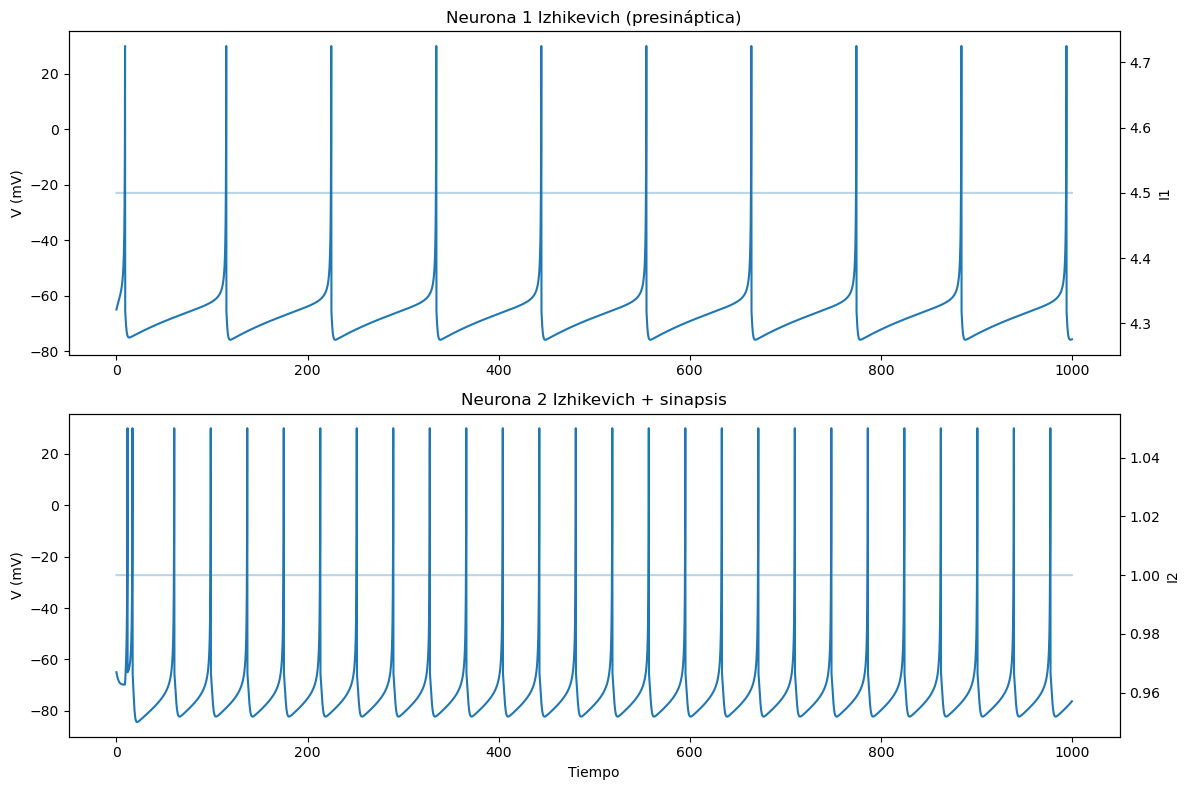

In [99]:
# ES_{CDP}
V1, V2 = mn.izhikevich(a1=0.02, b1=0.2, c1=-65.0, d1=8.0, a2=0.02, b2=0.2, c2=-65.0, d2=8.0, alpha=4.795, beta=0.003274, g_syn=0.7056, tmax=396.811)

## Identificación y validación del modelo de datos surrogados óptimo

Modelo de Phase Randomization (FFT)


========== Estadísticos ==========
Media original              : -67.102615
Media de las medias surrogate: 5.664594

Varianza original              : 56.988276
Media de las varianzas surrogate: 29.407573

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 100
Nivel de significación        : 0.05
Rechazos de H0               : 100/100
Porcentaje de rechazos       : 100.00%
Estadístico D medio          : 0.91053
p-valor medio                : 0.00000


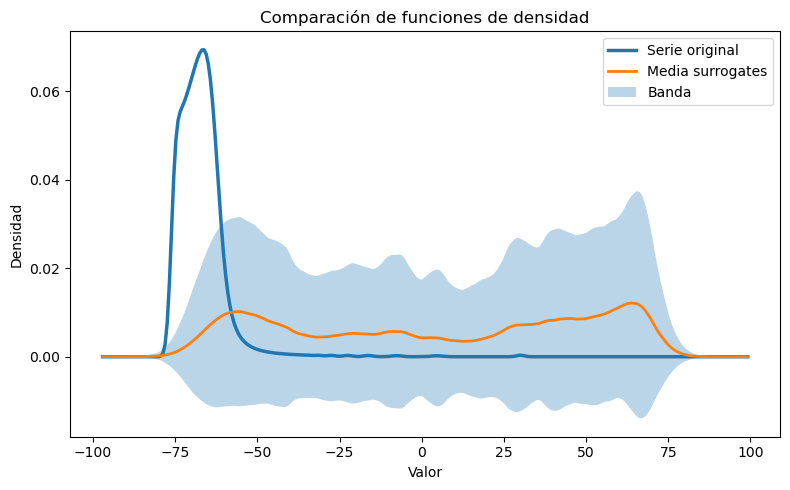


========== PSD ==========
Error relativo medio PSD: 46.131 %

========== Autocorrelación ==========
Error absoluto medio: 0.012973


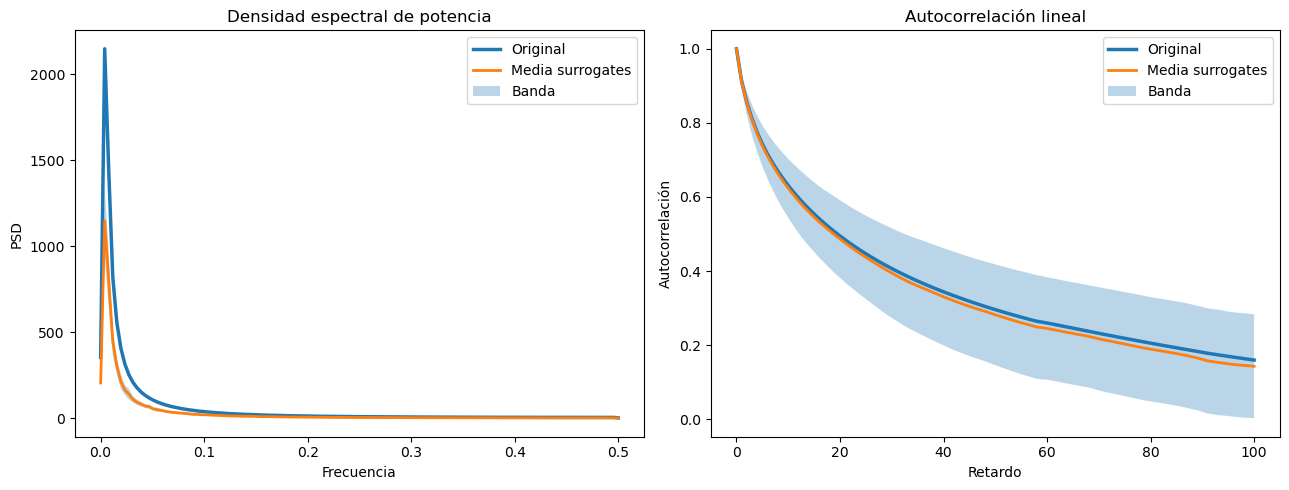


========== Información Mutua de Retardo ==========
Error absoluto medio : 6.991728
Retardos dentro de la banda : 0.00%


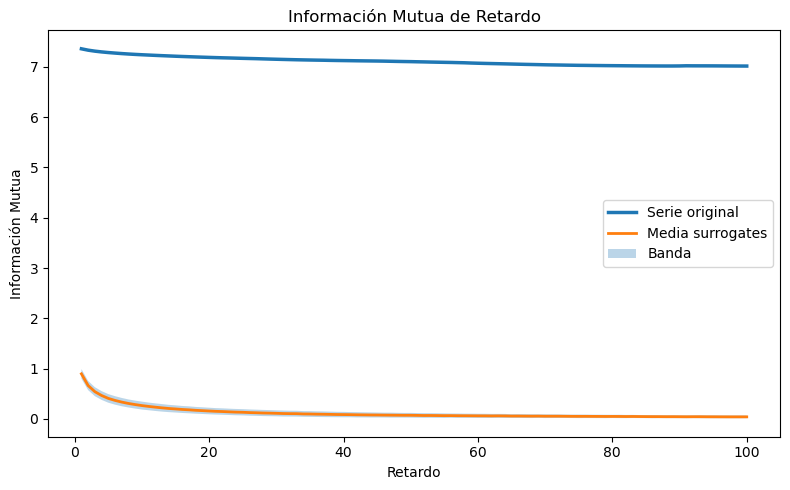

In [24]:
res_fft = validacion_surrogado(fft_surrogate, V1, n_surrogates=100)

Circular Shuffling (`circular`)


========== Estadísticos ==========
Media original              : -67.102615
Media de las medias surrogate: -67.102615

Varianza original              : 56.988276
Media de las varianzas surrogate: 56.988276

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 50
Nivel de significación        : 0.05
Rechazos de H0               : 0/50
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00000
p-valor medio                : 1.00000


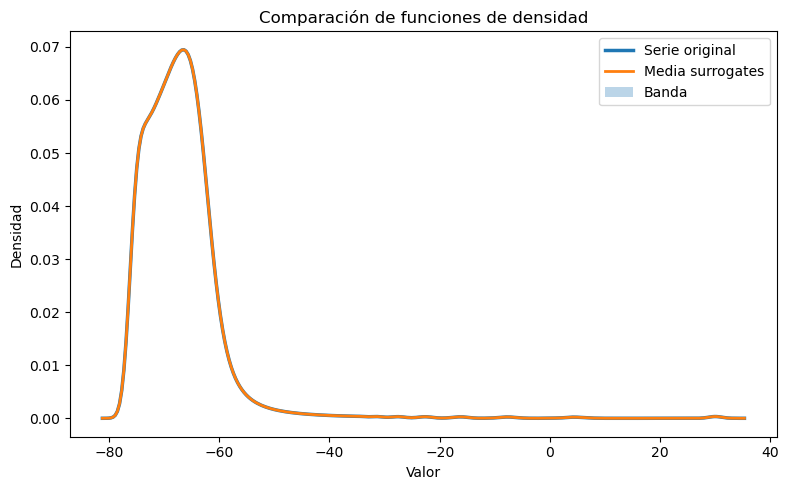


========== PSD ==========
Error relativo medio PSD: 8.596 %

========== Autocorrelación ==========
Error absoluto medio: 0.003847


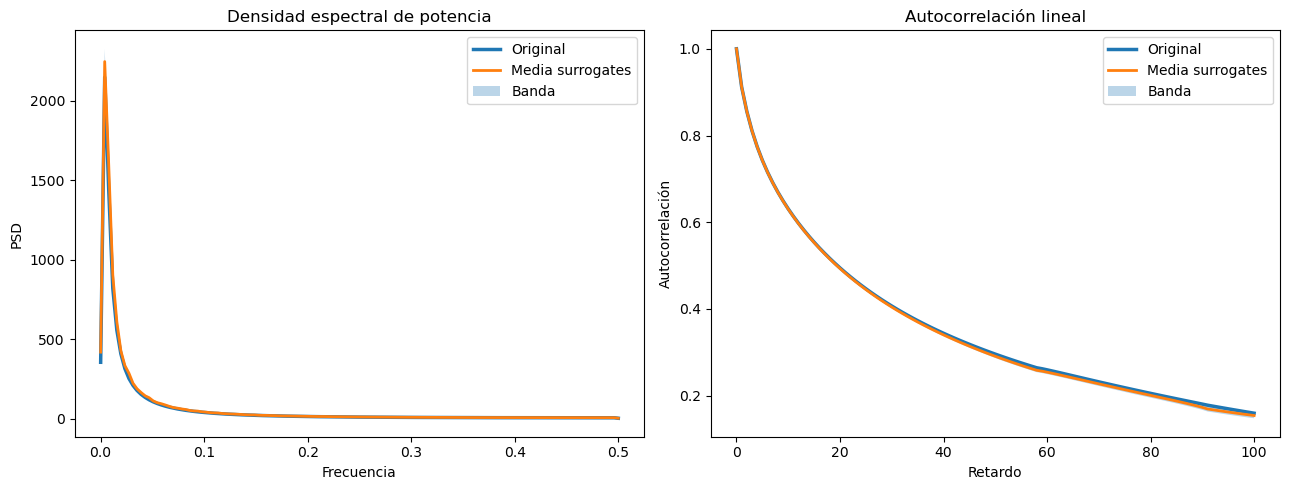


========== Información Mutua de Retardo ==========
Error absoluto medio : 0.046970
Retardos dentro de la banda : 0.00%


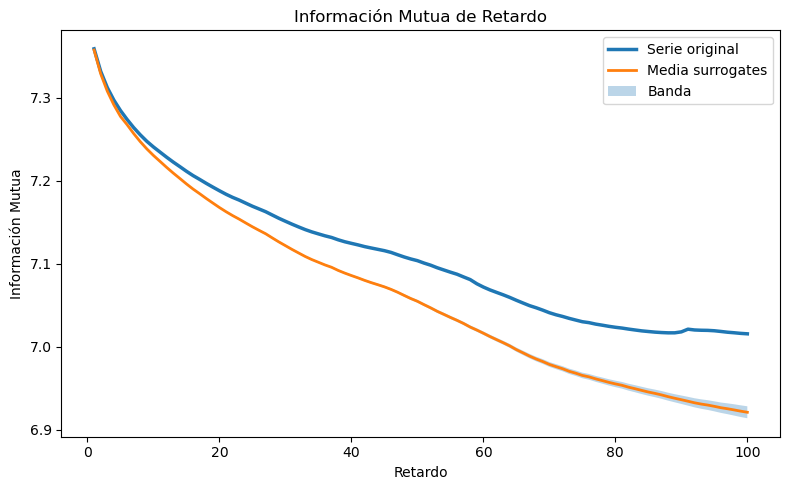

In [100]:
res_circular = validacion_surrogado(circular_surrogate, V1, n_surrogates=50, min=100, max=100)

Block Shuffling (`block`)


========== Estadísticos ==========
Media original              : -67.102615
Media de las medias surrogate: -67.131964

Varianza original              : 56.988276
Media de las varianzas surrogate: 54.805622

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 50
Nivel de significación        : 0.05
Rechazos de H0               : 50/50
Porcentaje de rechazos       : 100.00%
Estadístico D medio          : 0.05168
p-valor medio                : 0.00008


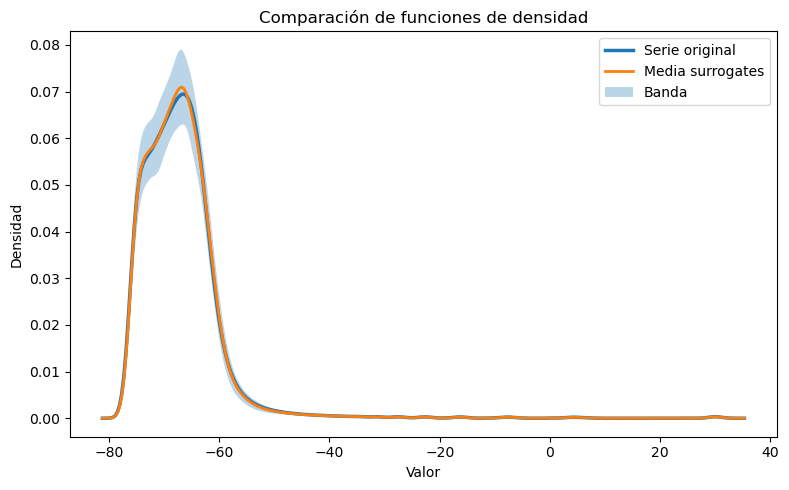


========== PSD ==========
Error relativo medio PSD: 22.670 %

========== Autocorrelación ==========
Error absoluto medio: 0.206829


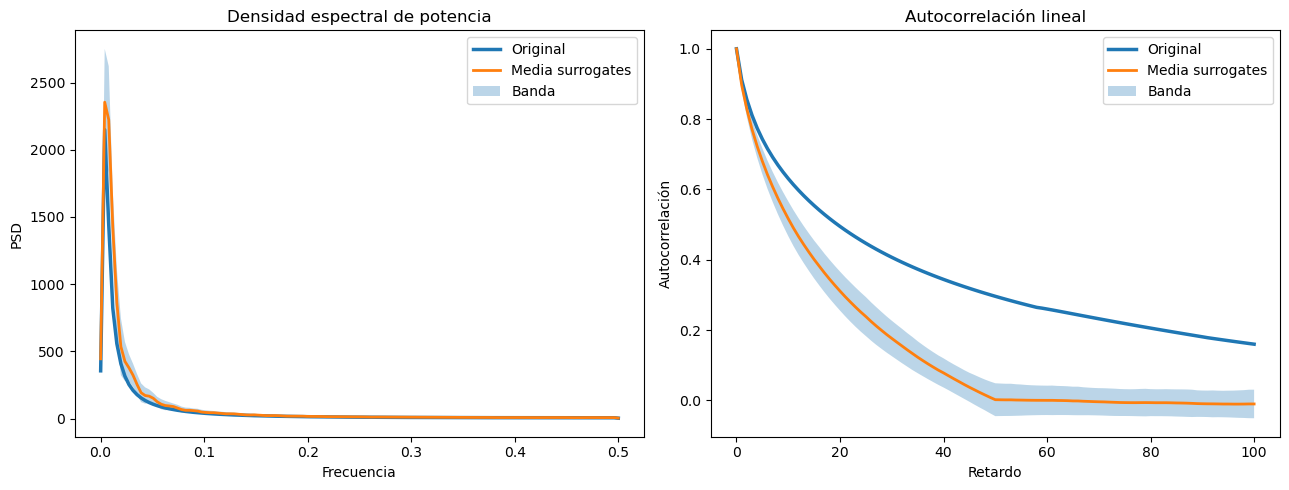


========== Información Mutua de Retardo ==========
Error absoluto medio : 4.145472
Retardos dentro de la banda : 0.00%


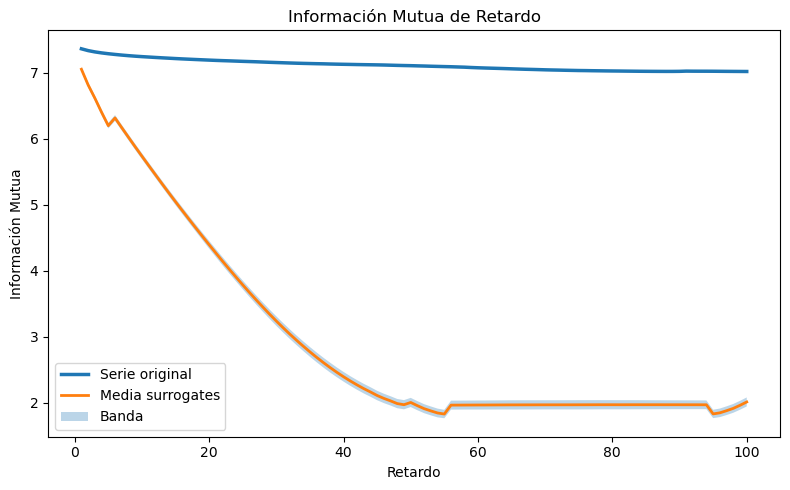

In [101]:
res_block = validacion_surrogado(block_surrogate, V1, n_surrogates=50, block_size=50)

Local Shuffling (`local`)


========== Estadísticos ==========
Media original              : -67.102615
Media de las medias surrogate: -67.102615

Varianza original              : 56.988276
Media de las varianzas surrogate: 56.988276


C:\Users\alons\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:586: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  res = hypotest_fun_out(*samples, **kwds)



========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 50
Nivel de significación        : 0.05
Rechazos de H0               : 0/50
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00072
p-valor medio                : 1.00000


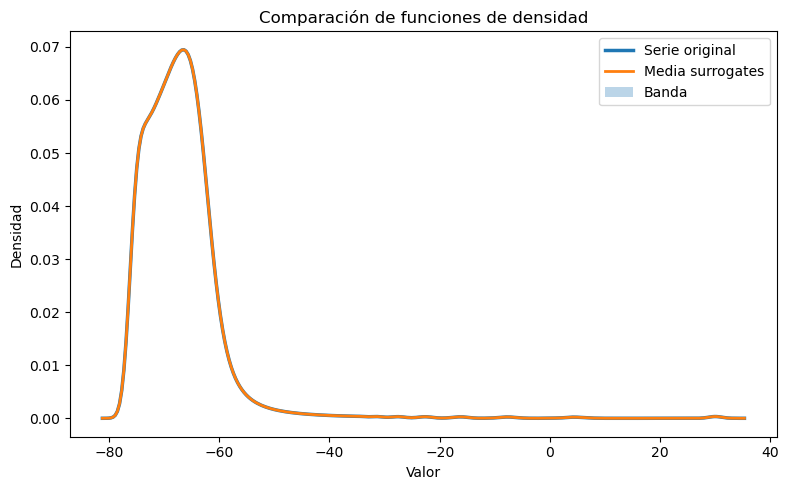


========== PSD ==========
Error relativo medio PSD: 600.476 %

========== Autocorrelación ==========
Error absoluto medio: 0.113735


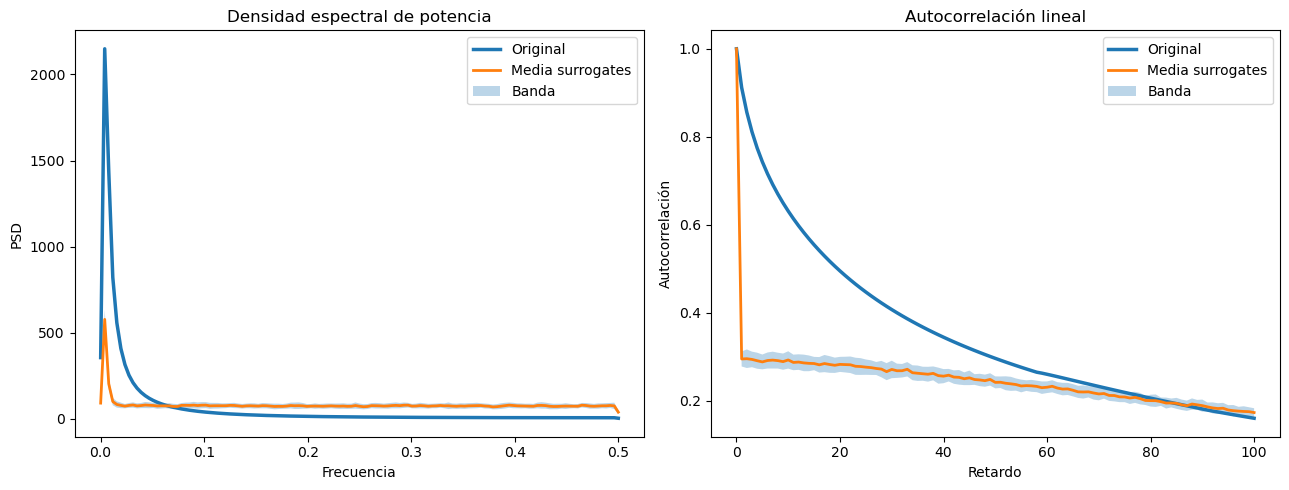


========== Información Mutua de Retardo ==========
Error absoluto medio : 6.362604
Retardos dentro de la banda : 0.00%


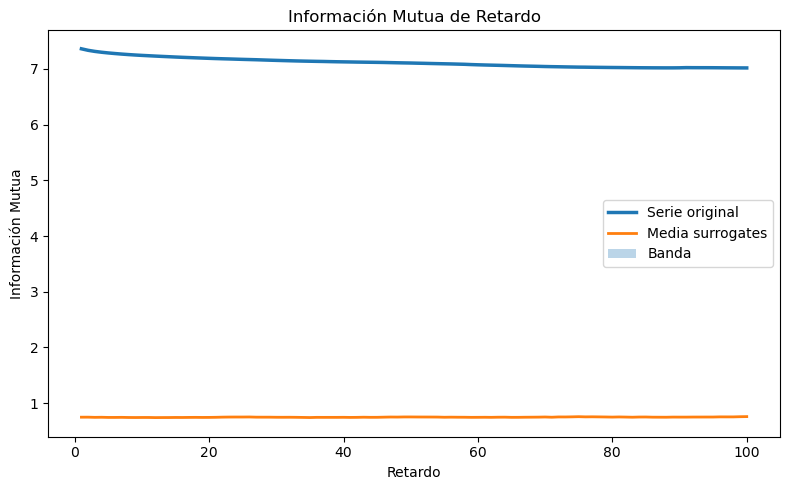

In [102]:
res_local = validacion_surrogado(local_surrogate, V1, n_surrogates=50, perm_range=50)

Random Shuffling (`random`)


========== Estadísticos ==========
Media original              : -67.102615
Media de las medias surrogate: -67.102615

Varianza original              : 56.988276
Media de las varianzas surrogate: 56.988276

========== Test Kolmogorov-Smirnov ==========
Número de surrogates          : 50
Nivel de significación        : 0.05
Rechazos de H0               : 0/50
Porcentaje de rechazos       : 0.00%
Estadístico D medio          : 0.00000
p-valor medio                : 1.00000


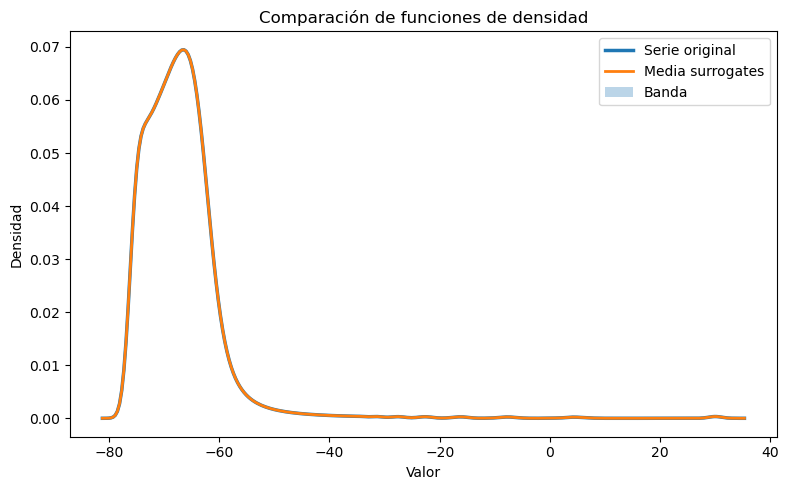


========== PSD ==========
Error relativo medio PSD: 953.877 %

========== Autocorrelación ==========
Error absoluto medio: 0.348662


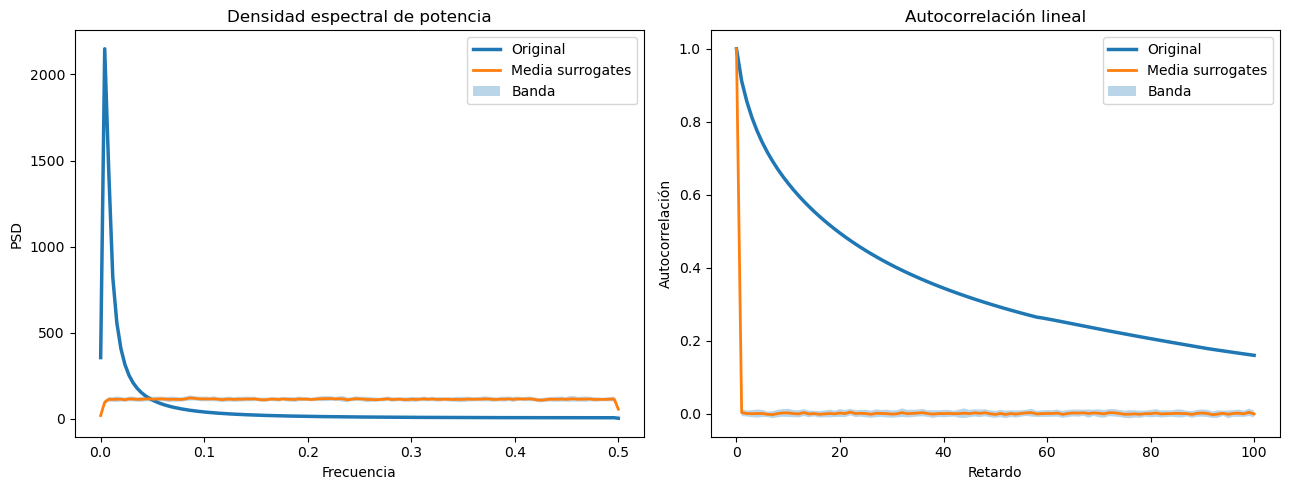


========== Información Mutua de Retardo ==========
Error absoluto medio : 7.112403
Retardos dentro de la banda : 0.00%


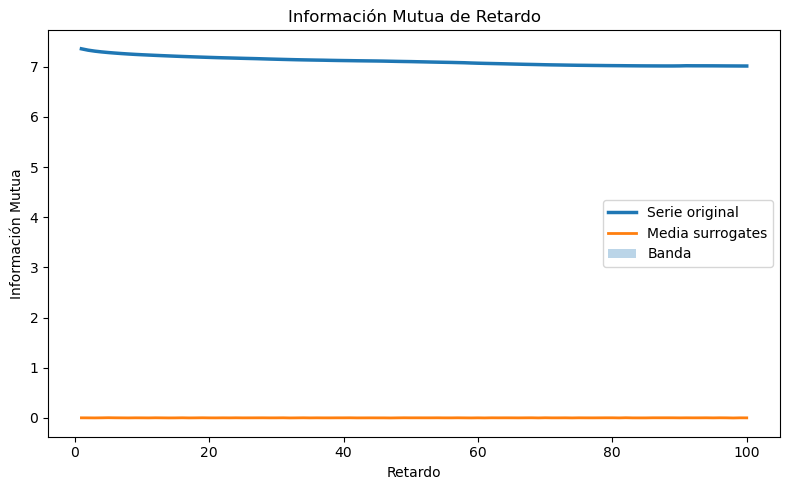

In [103]:
res_random = validacion_surrogado(random_surrogate, V1, n_surrogates=50)

## Fase exploratoria preliminar (perfiles de métrica frente al retardo)

Análisis de Tau: 100%|██████████| 400/400 [03:10<00:00,  2.10tau/s]


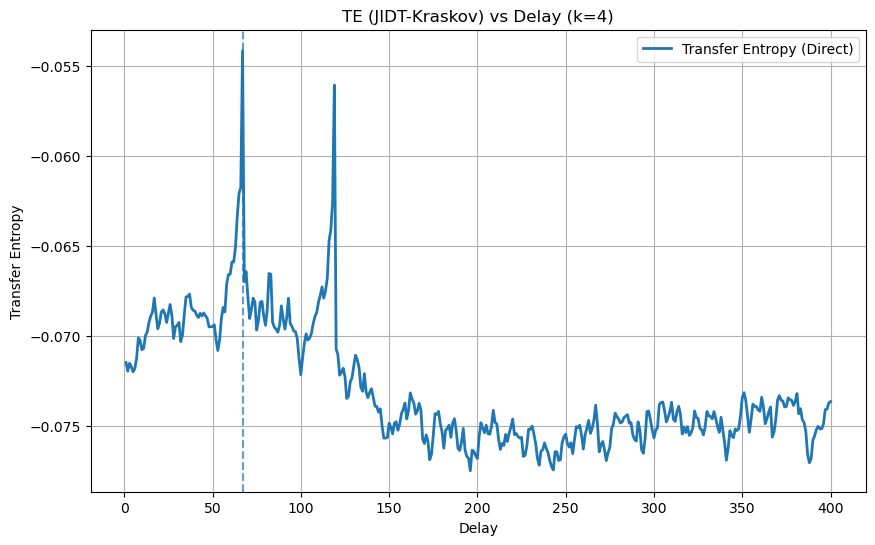

El delay óptimo para k=4 es: 67.000 ms


In [98]:
vecinos_values = np.array([4])
for n_vecinos in vecinos_values:
    taus, tes, best_tau = find_optimal_tau_TE_JIDT(V1, V2, n_vecinos=n_vecinos, max_steps=400, contexto_k=1, contexto_l=1, factor_bool= False, plot=True, inverse=False, conditional=False)

    print(f"El delay óptimo para k={n_vecinos} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 600/600 [00:24<00:00, 24.11lag/s]


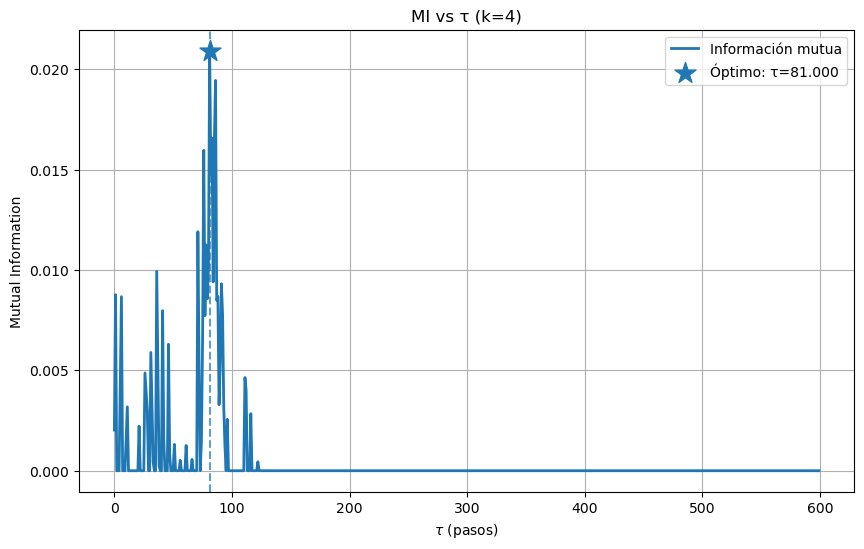

El desplazamiento óptimo para número de vecinos k=4 es: 81


In [68]:
mis, best_tau = find_optimal_tau_MI(V1, V2, n_vecinos=4, max_lags=600, milisegundos = False, plot= True)
print(f"El desplazamiento óptimo para número de vecinos k={4} es: {best_tau}")

## Contraste de significación estadística mediante datos surrogados

TE Original (V1 -> V2): -0.054134138520856245


Calculando surrogados: 100%|██████████| 200/200 [01:01<00:00,  3.24it/s]


Distribución nula - Media: -0.05936, Std: 0.00276
Pseudo p-valor: 0.03482587064676617


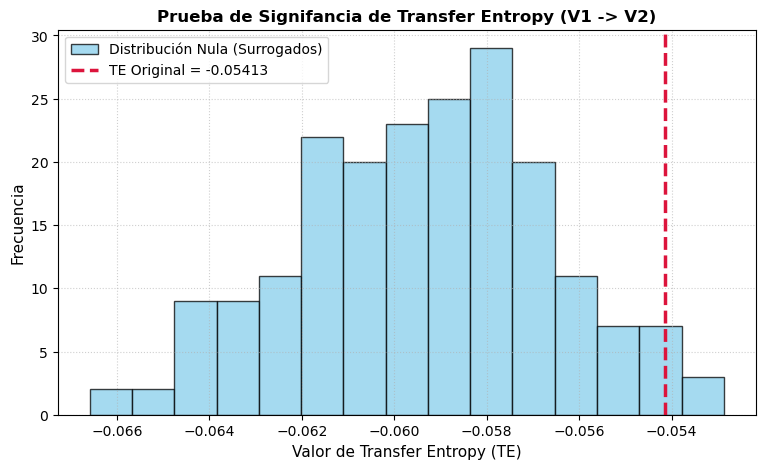

In [97]:
tau=67

V1 = V1.astype(float)
V2 = V2.astype(float)

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(V1.astype(np.float64), V2.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (V1 -> V2): {te_original}")

n_surrogates = 200
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    V1_surrogate = circular_surrogate(V1)

    teCalc.initialise()
    teCalc.setObservations(V1_surrogate.astype(np.float64), V2.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (V1 -> V2)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

## Análisis multivariado robusto de padres causales mediante IDTxl

In [40]:
data = np.vstack([V1, V2])
dataset = Data(data=data, dim_order='ps')

Adding data with properties: 2 processes, 10000 samples, 1 replications
overwriting existing data


In [41]:
settings = {
    # estimador JIDT
    'cmi_estimator': 'JidtKraskovCMI', 
    # máximo retardo a explorar
    'max_lag_sources': 200,             
    # mínimo retardo
    "tau_sources": 2,
    'min_lag_sources': 0, 
    # memoria del destino
    'max_lag_target': 5,           
    # número de permutaciones
    'n_perm_max_stat': 100,
    'n_perm_min_stat': 100,
    'n_perm_omnibus': 250, 
    'n_perm_max_seq': 250,     
    'alpha_max_stat': 0.1,
    'alpha_min_stat': 0.1,  
    'alpha_omnibus': 0.1,  
    'verbose': True,
    "permute_in_time": True,
    'perm_type': 'circular',
    'max_shift': 1000,
    'num_threads': 'USE_ALL'
}
network_analysis = MultivariateTE()
results1 = network_analysis.analyse_single_target(settings=settings, data=dataset, target=1, sources=[0])


Target: 1 - testing sources [0]

---------------------------- (1) include target candidates
candidate set: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5)]
testing candidate: (1, 1) maximum statistic, n_perm: 100
testing candidate: (1, 5) maximum statistic, n_perm: 100
 -- not significant

---------------------------- (2) include source candidates
candidate set: [(0, np.int64(0)), (0, np.int64(2)), (0, np.int64(4)), (0, np.int64(6)), (0, np.int64(8)), (0, np.int64(10)), (0, np.int64(12)), (0, np.int64(14)), (0, np.int64(16)), (0, np.int64(18)), (0, np.int64(20)), (0, np.int64(22)), (0, np.int64(24)), (0, np.int64(26)), (0, np.int64(28)), (0, np.int64(30)), (0, np.int64(32)), (0, np.int64(34)), (0, np.int64(36)), (0, np.int64(38)), (0, np.int64(40)), (0, np.int64(42)), (0, np.int64(44)), (0, np.int64(46)), (0, np.int64(48)), (0, np.int64(50)), (0, np.int64(52)), (0, np.int64(54)), (0, np.int64(56)), (0, np.int64(58)), (0, np.int64(60)), (0, np.int64(62)), (0, np.int64(64)), (0, np.int64(66)), 

RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO 1

Variables del TARGET utilizadas como embedding:
   Canal 1  -> lag -1

Variables FUENTE seleccionadas:
   Canal 0  lag - 68   TE = -0.070047   p = 0.0040

Resumen Ómnibus
   TE total : -0.070039
   p-valor  : 0.0040
   Resultado: SIGNIFICATIVO


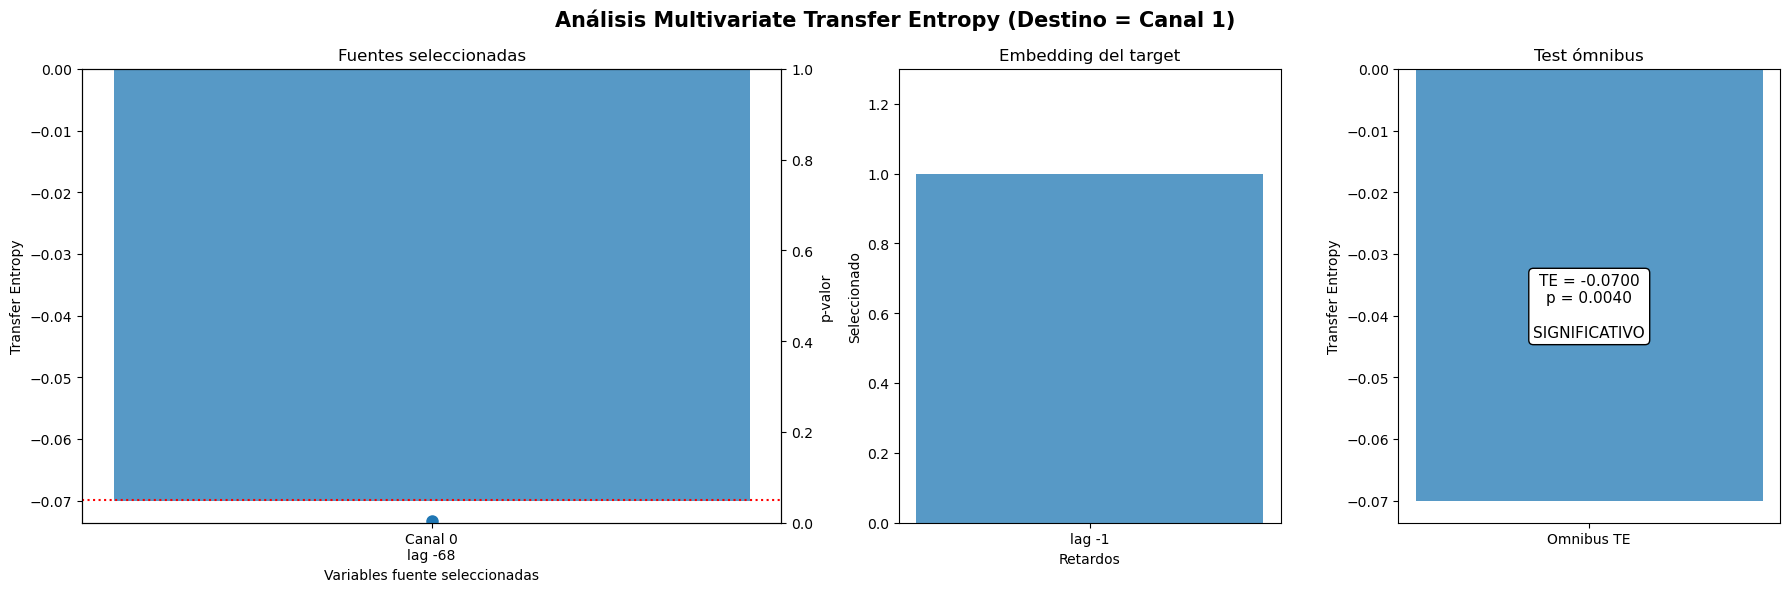

In [42]:
target = 1
res = results1.get_single_target(target=target, fdr=False)

selected_sources = res["selected_vars_sources"]
selected_target = res["selected_vars_target"]

te_values = np.asarray(res["selected_sources_te"])
p_values = np.asarray(res["selected_sources_pval"])

omnibus_te = res["omnibus_te"]
omnibus_p = res["omnibus_pval"]
omnibus_sign = res["omnibus_sign"]

print("="*70)
print(f"RESULTADOS DEL ANÁLISIS PARA EL CANAL DESTINO {target}")
print("="*70)

print("\nVariables del TARGET utilizadas como embedding:")
for lag in selected_target:
    print(f"   Canal {lag[0]}  -> lag -{lag[1]}")

print("\nVariables FUENTE seleccionadas:")
for var, te, p in zip(selected_sources, te_values, p_values):
    print(f"   Canal {var[0]}  lag -{var[1]:3d}   "
          f"TE = {te:.6f}   p = {p:.4f}")

print("\nResumen Ómnibus")
print(f"   TE total : {omnibus_te:.6f}")
print(f"   p-valor  : {omnibus_p:.4f}")
print(f"   Resultado: {'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")

print("="*70)

fig = plt.figure(figsize=(18,6))
gs = fig.add_gridspec(1,3,width_ratios=[2.2,1.2,1.2])
ax1 = fig.add_subplot(gs[0])
if len(selected_sources)>0:

    labels = [f"Canal {v[0]}\nlag -{v[1]}" for v in selected_sources]
    x = np.arange(len(labels))
    ax1.bar(x, te_values, width=0.45, alpha=0.75, label="Transfer Entropy")
    ax1.set_ylabel("Transfer Entropy")
    ax1.set_xlabel("Variables fuente seleccionadas")
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels)
    ax1_t = ax1.twinx()
    ax1_t.plot(x, p_values, "o--", linewidth=2, markersize=8, label="p-valor")
    ax1_t.axhline(0.05, color="red", linestyle=":", label="α = 0.05")
    ax1_t.set_ylabel("p-valor")
    ax1_t.set_ylim(0,1)
    ax1.set_title("Fuentes seleccionadas")
else:
    ax1.text(0.5, 0.5, "No se seleccionó ninguna fuente", ha="center", va="center", fontsize=12)

ax2 = fig.add_subplot(gs[1])
if len(selected_target)>0:
    labels = [f"lag -{v[1]}" for v in selected_target]
    x = np.arange(len(labels))
    ax2.bar(x, np.ones(len(labels)), alpha=0.75)
    ax2.set_ylim(0,1.3)
    ax2.set_xticks(x)
    ax2.set_xticklabels(labels)
    ax2.set_ylabel("Seleccionado")
    ax2.set_xlabel("Retardos")
    ax2.set_title("Embedding del target")
else:
    ax2.text(0.5, 0.5, "Sin memoria seleccionada", ha="center", va="center", fontsize=12)
ax3 = fig.add_subplot(gs[2])
ax3.bar(["Omnibus TE"], [omnibus_te], alpha=0.75, width=0.5)
texto = (f"TE = {omnibus_te:.4f}\n" f"p = {omnibus_p:.4f}\n\n" f"{'SIGNIFICATIVO' if omnibus_sign else 'NO SIGNIFICATIVO'}")
ax3.text(0, omnibus_te*0.55, texto, ha="center", va="center", fontsize=11, bbox=dict(boxstyle="round", facecolor="white"))
ax3.set_ylabel("Transfer Entropy")
ax3.set_title("Test ómnibus")
plt.suptitle(f"Análisis Multivariate Transfer Entropy (Destino = Canal {target})", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()